# Spatial model families and neural estimation

This companion covers every max-stable spatial model implemented in `spatial_extremes` and the optional amortized neural estimator. It uses a fixed synthetic station layout and simulated unit-Frechet fields for a controlled demonstration; no network data is required.

## Sections
1. Setup and prepare a small site layout
2. Compare Smith, Schlather, and Brown-Resnick models
3. Fit and compare the three models by pairwise likelihood
4. Train and use the optional neural estimator
5. Choosing a model and interpreting estimates

For the marginal GEV workflow and empirical dependence summaries, see [the main walkthrough](./spatial_extremes_walkthrough.ipynb). For both Bayesian workflows, see [Bayesian workflows](./spatial_extremes_bayesian.ipynb).

## 1. Setup and prepare a small site layout

Install the project from its root with `python -m pip install -e ".[plotting,neural]"`. The neural extra installs joblib and scikit-learn; the plotting extra installs Matplotlib. The neural estimator is trained for one specific coordinate layout and replicate count, so we use the same fixed layout for every training and prediction dataset.

In [8]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from scipy.spatial.distance import pdist

candidates = (Path.cwd(), *Path.cwd().parents)
PROJECT_ROOT = next(
    (
        path
        for path in candidates
        if (path / "Dummy_data" / "extremes_observations.parquet").is_file()
        and (path / "src" / "spatial_extremes").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from the repository checkout.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from spatial_extremes import fit_pairwise_likelihood
from spatial_extremes.models import BrownResnickModel, SchlatherModel, SmithModel
from spatial_extremes.plotting import plot_spatial_field

SEED = 2718
observations = pl.read_parquet(PROJECT_ROOT / "Dummy_data" / "extremes_observations.parquet")
site_metadata = (
    observations
    .select("station_id", "lon", "lat")
    .unique(subset="station_id", maintain_order=True)
    .head(8)
)
site_names = site_metadata.get_column("station_id").to_list()
longitude = site_metadata.get_column("lon").to_numpy()
latitude = site_metadata.get_column("lat").to_numpy()
coordinates = np.column_stack(
    [
        (longitude + 79.0) * 111.0 * np.cos(np.deg2rad(44.0)),
        (latitude - 44.0) * 111.0,
    ]
)
print(f"Using {len(site_names)} sites; median pair distance = {np.median(pdist(coordinates)):.1f} km")

Using 8 sites; median pair distance = 252.2 km


## 2. Compare the three max-stable spatial models

All three model classes provide `extremal_coefficient`, `bivariate_cdf`, `bivariate_logpdf`, and `simulate`. Their simulators return unit-Frechet margins.

- **Smith** uses a bivariate Gaussian storm kernel with a positive-definite covariance matrix. It naturally represents geometric anisotropy; larger covariance eigenvalues spread storms over greater distances.
- **Schlather** uses an extremal Gaussian process with a powered-exponential correlation. Its extremal coefficient approaches `1 + sqrt(1/2)`, not 2, as correlation tends to zero, so it cannot represent full pairwise independence.
- **Brown-Resnick** uses a Gaussian process with stationary increments and a power variogram `gamma(h) = (|h| / range)**alpha`. The exponent controls roughness; the default power variogram is isotropic, while custom variograms can extend it.

The parameter values below are chosen only to illustrate each API and produce fields on this layout. They are not estimates from the rainfall measurements.

In [9]:
models = {
    "Smith": SmithModel(
        cov=np.array([[180.0**2, 0.25 * 180.0 * 130.0], [0.25 * 180.0 * 130.0, 130.0**2]])
    ),
    "Schlather": SchlatherModel(range_=250.0, smoothness=1.0),
    "Brown-Resnick": BrownResnickModel(range_=250.0, alpha=1.0),
}

reference_distance = float(np.median(pdist(coordinates)))
h = np.array([reference_distance, 0.0])
for name, model in models.items():
    print(f"{name:14s} extremal coefficient at h={reference_distance:.1f} km: "
          f"{model.extremal_coefficient(h):.3f}")

Smith          extremal coefficient at h=252.2 km: 1.531
Schlather      extremal coefficient at h=252.2 km: 1.564
Brown-Resnick  extremal coefficient at h=252.2 km: 1.522


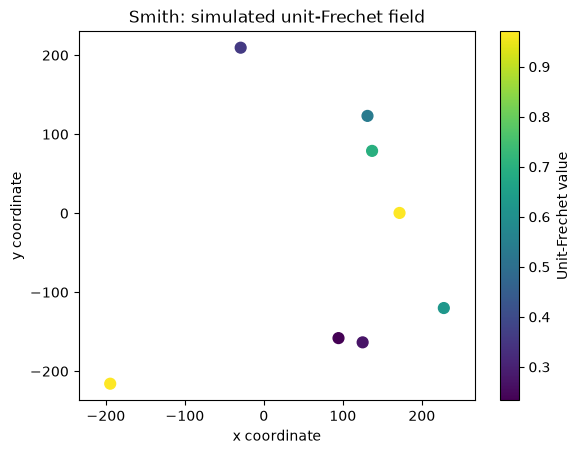

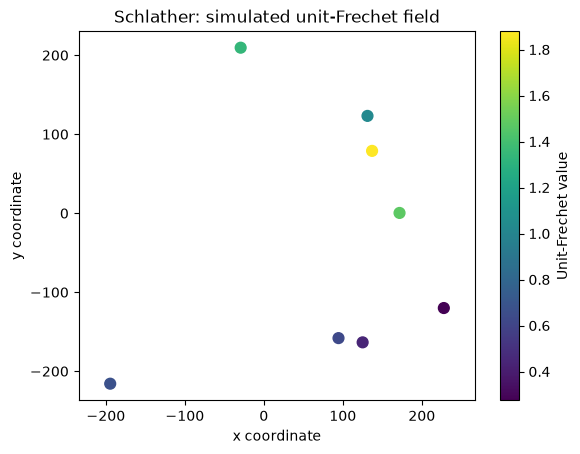

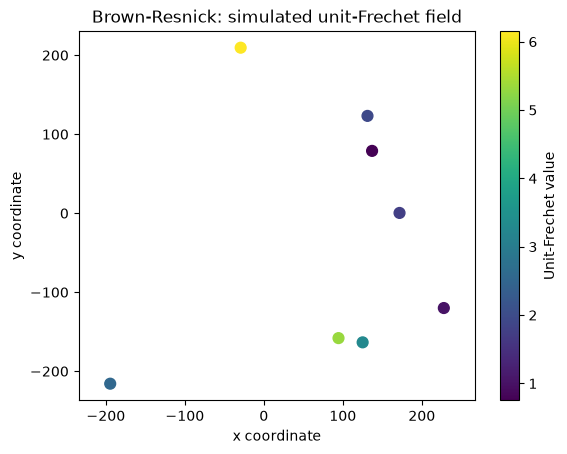

In [10]:
for index, (name, model) in enumerate(models.items()):
    field = model.simulate(
        coordinates,
        n_reps=1,
        rng=np.random.default_rng(SEED + index),
    )[0]
    fig, ax = plot_spatial_field(
        field,
        coordinates,
        title=f"{name}: simulated unit-Frechet field",
        colorbar_label="Unit-Frechet value",
    )
    plt.show()

## 3. Fit and compare models with pairwise likelihood

To make the fitting API concrete, generate independent replicates from a known Brown-Resnick process and fit each of the three model classes to the same observations. This is a model-misspecification exercise: Smith and Schlather are deliberately being fit to Brown-Resnick data. The three composite negative log-likelihood values are useful diagnostics, but do not treat them as a formal model-selection score or compare them as if these were full likelihoods.

`x0_free` uses each model's unconstrained fitting parameterization. The Smith model has three free Cholesky parameters; the other two have log-range and a transformed shape parameter.

In [11]:
truth = BrownResnickModel(range_=reference_distance, alpha=1.0)
simulated_data = truth.simulate(
    coordinates,
    n_reps=120,
    rng=np.random.default_rng(SEED),
)
site_columns = [f"site_{i}" for i in range(len(site_names))]
frechet_data = pl.DataFrame(simulated_data, schema=site_columns, orient="row")
print("Simulated unit-Frechet data shape:", simulated_data.shape)
frechet_data.head()

Simulated unit-Frechet data shape: (120, 8)


site_0,site_1,site_2,site_3,site_4,site_5,site_6,site_7
f64,f64,f64,f64,f64,f64,f64,f64
3.645635,3.832736,11.239949,7.225335,11.502969,37.193673,15.558168,8.596326
0.337613,0.357852,0.681431,0.568103,0.325942,1.695333,0.50812,0.641403
10.837987,10.090222,6.211579,5.481652,5.376203,2.571715,3.07174,7.50956
1.39774,1.173899,2.957564,2.756991,15.251763,6.151834,2.755542,1.356341
0.27938,0.846645,1.128877,0.516846,0.57864,0.493821,0.377742,0.278289


In [12]:
initial_range = float(np.median(pdist(coordinates)))
initial_values = {
    SmithModel: np.array([np.log(initial_range), 0.0, np.log(initial_range)]),
    SchlatherModel: np.array([np.log(initial_range), 0.0]),
    BrownResnickModel: np.array([np.log(initial_range), 0.0]),
}
fit_results = {}
for model_class, x0 in initial_values.items():
    fit_results[model_class.__name__] = fit_pairwise_likelihood(
        model_class,
        frechet_data,
        coordinates,
        x0_free=x0,
        rng=np.random.default_rng(SEED),
    )

for name, result in fit_results.items():
    model = result.model
    params = (
        f"range={model.range_:.1f}, shape={getattr(model, 'alpha', getattr(model, 'smoothness', float('nan'))):.2f}"
        if hasattr(model, "range_")
        else f"covariance=\n{model.cov}"
    )
    print(f"{name}: converged={result.converged}, pairs={result.n_pairs_used}, "
          f"composite NLL={result.nllh:.2f}, {params}")

SmithModel: converged=True, pairs=28, composite NLL=12726.75, covariance=
[[26706.73571214 21888.9472343 ]
 [21888.9472343  35970.6301693 ]]
SchlatherModel: converged=True, pairs=28, composite NLL=12619.14, range=271.1, shape=1.00
BrownResnickModel: converged=True, pairs=28, composite NLL=12498.51, range=276.2, shape=0.94


## 4. Optional neural estimator (Brown-Resnick or Schlather)

`NeuralEstimator` is a simulation-based amortized estimator, not a generic neural network fit or a replacement for all models. It supports isotropic Brown-Resnick (`"brownresnick"`) and Schlather (`"schlather"`), but not Smith. The implementation simulates training datasets over a prior, converts each to binned dependence summaries, and learns a posterior-mean estimate of `(range, shape)` for one fixed site layout and replicate count.

This small run uses a reduced training set to keep the demonstration tractable. Production use generally needs more simulated training datasets and held-out evaluation. `predict_bootstrap` resamples replicate rows to show sampling variability; it is not a posterior interval. Train on a fixed seed, and compare against pairwise likelihood as an independent check.

In [13]:
from spatial_extremes.neural_estimator import NeuralEstimator

neural_replicates = 30
neural_truth = BrownResnickModel(range_=0.8 * reference_distance, alpha=1.1)
neural_data = neural_truth.simulate(
    coordinates,
    n_reps=neural_replicates,
    rng=np.random.default_rng(SEED + 1),
)
estimator = NeuralEstimator(
    model="brownresnick",
    coords=coordinates,
    n_reps=neural_replicates,
    n_bins=6,
    hidden=(32, 16),
    seed=SEED,
).fit(n_train=120, n_jobs=1)

estimate = estimator.predict(neural_data)
bootstrap_draws = estimator.predict_bootstrap(neural_data, n_boot=100, seed=SEED)
print("Truth (range, alpha):", (neural_truth.range_, neural_truth.alpha))
print("Neural estimate (range, alpha):", estimate)
print("Bootstrap 10%-90% ranges:", np.quantile(bootstrap_draws, [0.1, 0.9], axis=0))

# Schlather is the other supported neural model; its second estimate is smoothness.
schlather_truth = SchlatherModel(range_=0.8 * reference_distance, smoothness=1.1)
schlather_data = schlather_truth.simulate(
    coordinates,
    n_reps=neural_replicates,
    rng=np.random.default_rng(SEED + 2),
)
schlather_estimator = NeuralEstimator(
    model="schlather",
    coords=coordinates,
    n_reps=neural_replicates,
    n_bins=6,
    hidden=(32, 16),
    seed=SEED,
).fit(n_train=120, n_jobs=1)
print("Schlather truth (range, smoothness):", (schlather_truth.range_, schlather_truth.smoothness))
print("Schlather neural estimate:", schlather_estimator.predict(schlather_data))

simulated 120 datasets in 8s; training network...
done. epochs=187, best val score (R^2)=0.878
Truth (range, alpha): (201.73349865259732, 1.1)
Neural estimate (range, alpha): [227.89239207   0.88749241]
Bootstrap 10%-90% ranges: [[115.12052728   0.74702073]
 [350.54059818   1.11922333]]
simulated 120 datasets in 1s; training network...
done. epochs=111, best val score (R^2)=0.426
Schlather truth (range, smoothness): (201.73349865259732, 1.1)
Schlather neural estimate: [160.31796117   1.08414108]


In [14]:
# A small held-out comparison. Increase n_test for a more stable assessment.
evaluation = estimator.evaluate(n_test=10, n_compare=2, verbose=False)
print(evaluation["table"].to_dicts())
print("Seconds per neural prediction:", round(evaluation["seconds_per_fit_nn"], 4))

# Optional persistence for reuse with this exact layout and replicate count:
# estimator.save(PROJECT_ROOT / "neural_brownresnick_demo.joblib")
# loaded_estimator = NeuralEstimator.load(PROJECT_ROOT / "neural_brownresnick_demo.joblib")

[{'method': 'neural (all 10)', 'RMSE log(range)': 0.419387731718463, 'RMSE shape': 0.13922058706751053, 'MAE theta(h_med)': 0.0453124012181241}, {'method': 'neural (same 2)', 'RMSE log(range)': 0.2957202532910851, 'RMSE shape': 0.10352047719749227, 'MAE theta(h_med)': 0.02372659755146944}, {'method': 'pairwise lik. (same 2)', 'RMSE log(range)': 3.5299855737095425, 'RMSE shape': 0.6360093684263104, 'MAE theta(h_med)': 0.05075246423607871}]
Seconds per neural prediction: 0.0001


## 5. Choosing a model and interpreting estimates

- Use **Smith** when Gaussian storm geometry and anisotropy are scientifically appropriate. `SmithModel.simulate_geo` is available for GeoPandas point layers in a projected CRS; install the `geo` extra if needed.
- Use **Schlather** when an extremal-Gaussian construction is suitable, remembering its extremal-coefficient ceiling. Its correlation function must produce valid site correlation matrices for simulation.
- Use **Brown-Resnick** for variogram-based dependence with a flexible power exponent. A custom variogram must be valid (conditionally negative definite); the package does not validate this property for you.
- Pairwise likelihood works with all three classes, requires correctly ordered two-dimensional projected coordinates, and assumes independent replicates with unit-Frechet margins. Fit success does not establish model adequacy.
- The neural estimator is an optional prior-dependent shortcut only for isotropic Brown-Resnick/Schlather. It is layout-specific, trained at one replicate count, and expects complete unit-Frechet data. Its bootstrap spread is not full Bayesian posterior uncertainty.

For Bayesian parameter uncertainty from pairwise likelihood and the separate spatio-temporal Bayesian GEV margin model, continue to [Bayesian workflows](./spatial_extremes_bayesian.ipynb).